# TARDIS
This notebook loads the dataset, cleans the data, handles missing values, and creates new features for further analysis.

In [119]:
import pandas as pd
import numpy as np

## Load and Inspect the Dataset

In [120]:
df = pd.read_csv("dataset.csv")
print("(Nb rows, Nb columns): ", df.shape)
df.info()

(Nb rows, Nb columns):  (40, 6)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40 entries, 0 to 39
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   date               40 non-null     object 
 1   departure_station  39 non-null     object 
 2   arrival_station    39 non-null     object 
 3   scheduled_time     37 non-null     object 
 4   actual_time        36 non-null     object 
 5   delay_minutes      30 non-null     float64
dtypes: float64(1), object(5)
memory usage: 2.0+ KB


In [121]:
df.head()

,date,departure_station,arrival_station,scheduled_time,actual_time,delay_minutes
0,2024-02-01,Paris,Marseille,08:00,08:10,10.0
1,2024-02-01,Bordeaux,Lyon,09:15,09:20,5.0
2,2024-02-02,Lyon,Paris,07:30,07:40,10.0
3,2024-02-02,Marseille,Bordeaux,10:00,10:30,30.0
4,2024-02-03,Nice,Lille,12:45,12:50,5.0


In [122]:
print(df.columns)

Index(['date', 'departure_station', 'arrival_station', 'scheduled_time',
       'actual_time', 'delay_minutes'],
      dtype='object')


In [123]:
nb_duplicates = df.duplicated().sum()

if nb_duplicates > 0:
    df = df.drop_duplicates()

print("Nb duplicates: ", nb_duplicates)
print("(Nb rows, Nb columns): ", df.shape)

Nb duplicates:  0
(Nb rows, Nb columns):  (40, 6)


## Data Cleaning

In [124]:
df["date"] = pd.to_datetime(df["date"], errors="coerce")

df["scheduled_time"] = pd.to_datetime(
    df["scheduled_time"].astype(str).str.replace("-", ":"),
    format="%H:%M",
    errors="coerce"
).dt.time

df["actual_time"] = pd.to_datetime(
    df["actual_time"].astype(str).str.replace("-", ":"),
    format="%H:%M",
    errors="coerce"
).dt.time

df["delay_minutes"] = pd.to_numeric(df["delay_minutes"], errors="coerce")
df.loc[df["delay_minutes"] < 0, "delay_minutes"] = np.nan

In [125]:
df["departure_station"] = df["departure_station"].fillna("Unknown").str.strip()
df["arrival_station"] = df["arrival_station"].fillna("Unknown").str.strip()

In [126]:
print(df.isnull().sum())

date                 26
departure_station     0
arrival_station       0
scheduled_time       16
actual_time          22
delay_minutes        11
dtype: int64


The dataset is checked for missing values so that incomplete rows or invalid values can be handled before feature creation.

In [127]:
df = df.dropna(subset=["date", "scheduled_time", "actual_time", "delay_minutes"])
print("(Nb rows, Nb columns): ", df.shape)

(Nb rows, Nb columns):  (10, 6)


Rows with missing values in the key columns are removed because these fields are necessary for reliable analysis and later feature engineering.

## Feature Engineering

New features are created from the original columns to make the dataset easier to analyze. In this section, temporal features such as year, month, quarter, season, and scheduled hour are added, as well as route, peak-hour, and delay-category features.

In [128]:
df['Year'] = df['date'].dt.year
df['Month'] = df['date'].dt.month

In [129]:
df["Month name"] = df["date"].dt.month_name()
df["Quarter"] = df["date"].dt.quarter

In [130]:
df["Season"] = df["Month"].map({
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Autumn", 10: "Autumn", 11: "Autumn"
})

In [131]:
df["Route"] = df["departure_station"] + " -> " + df["arrival_station"]

In [132]:
df["scheduled_hour"] = df["scheduled_time"].apply(
    lambda x: x.hour if pd.notnull(x) else np.nan
)

In [133]:
df["is_peak_hour"] = df["scheduled_hour"].apply(
    lambda x: 1 if x in [7, 8, 9, 17, 18, 19] else 0
)

In [134]:
df["delay_category"] = pd.cut(
    df["delay_minutes"],
    bins=[-1, 5, 15, 30, float("inf")],
    labels=["On time / slight", "Short delay", "Medium delay", "Long delay"]
)

In [135]:
df[["Year", "Month", "scheduled_hour", "is_peak_hour", "delay_category", "Route"]].head()

,Year,Month,scheduled_hour,is_peak_hour,delay_category,Route
0,2024,2,8,1,Short delay,Paris -> Marseille
1,2024,2,9,1,On time / slight,Bordeaux -> Lyon
2,2024,2,7,1,Short delay,Lyon -> Paris
3,2024,2,10,0,Medium delay,Marseille -> Bordeaux
4,2024,2,12,0,On time / slight,Nice -> Lille


In [136]:
df.to_csv('cleaned_dataset.csv', index=False)

## Delay Minutes Analysis

In [137]:
df["delay_minutes"].describe()

count    10.000000
mean     18.000000
std      12.292726
min       5.000000
25%       6.250000
50%      15.000000
75%      30.000000
max      35.000000
Name: delay_minutes, dtype: float64

In [138]:
print("Mean delay:", df["delay_minutes"].mean())
print("Median delay:", df["delay_minutes"].median())
print("Minimum delay:", df["delay_minutes"].min())
print("Maximum delay:", df["delay_minutes"].max())

Mean delay: 18.0
Median delay: 15.0
Minimum delay: 5.0
Maximum delay: 35.0


<Axes: title={'center': 'Distribution of delay minutes'}, ylabel='Frequency'>

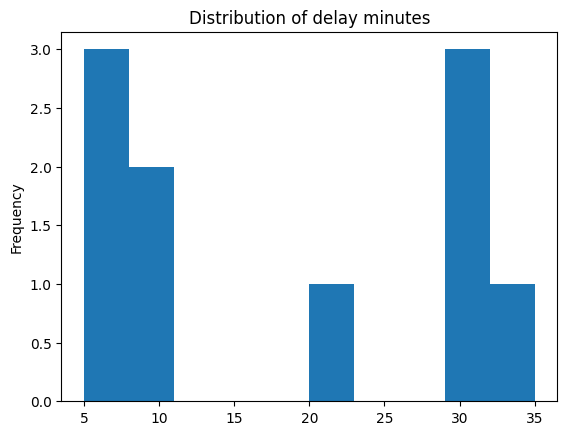

In [139]:
df["delay_minutes"].plot(kind="hist", bins=10, title="Distribution of delay minutes")

The average delay is 18 minutes and the median delay is 15 minutes. This suggests that most delays are moderate, but some larger delays may increase the average. The delay values range from 5 to 35 minutes, showing that the dataset includes both shorter and longer delays.

<Axes: title={'center': 'Boxplot of delay minutes'}>

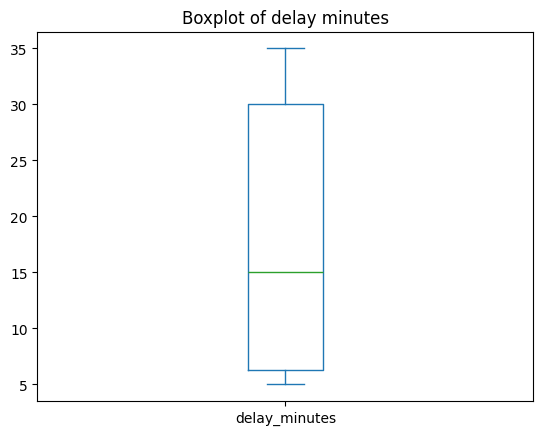

In [140]:
df["delay_minutes"].plot(kind="box", title="Boxplot of delay minutes")

In [141]:
df.sort_values("delay_minutes", ascending=False).head()

,date,departure_station,arrival_station,scheduled_time,actual_time,delay_minutes,Year,Month,Month name,Quarter,Season,Route,scheduled_hour,is_peak_hour,delay_category
6,2024-02-04,Paris,Bordeaux,08:15:00,08:50:00,35.0,2024,2,February,1,Winter,Paris -> Bordeaux,8,1,Long delay
3,2024-02-02,Marseille,Bordeaux,10:00:00,10:30:00,30.0,2024,2,February,1,Winter,Marseille -> Bordeaux,10,0,Medium delay
7,2024-02-05,Marseille,Lyon,09:45:00,10:15:00,30.0,2024,2,February,1,Winter,Marseille -> Lyon,9,1,Medium delay
37,2024-02-16,Bordeaux,Paris,16:01:00,12:30:00,30.0,2024,2,February,1,Winter,Bordeaux -> Paris,16,0,Medium delay
24,2024-02-27,Strasbourg,Strasbourg,12:30:00,18:31:00,20.0,2024,2,February,1,Winter,Strasbourg -> Strasbourg,12,0,Medium delay


## Average Delay by Departure Station

In [142]:
departure_delay = df.groupby("departure_station")["delay_minutes"].mean().sort_values(ascending=False)
departure_delay

departure_station
Marseille     30.0
Paris         22.5
Strasbourg    20.0
Bordeaux      17.5
Lyon          10.0
Lille          5.0
Nice           5.0
Name: delay_minutes, dtype: float64

<Axes: title={'center': 'Average Delay by Departure Station'}, xlabel='departure_station'>

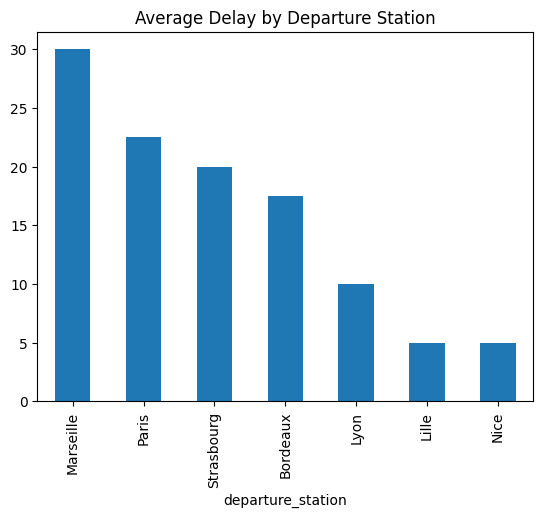

In [143]:
departure_delay.plot(kind="bar", title="Average Delay by Departure Station")

This analysis compares the average delay across departure stations. Grouping the data by `departure_station` helps identify whether some stations tend to have higher delays than others. The bar chart makes it easier to compare stations and observe which ones have the highest average delay.